In [70]:
# Descomentar las líneas de los módulos que no tengas instalados
# !pip install opencv-python
# !pip install numpy
# !pip install matplotlib
# !pip install pandas
# !pip install torch torchvision

In [71]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv 
import pandas as pd
from pathlib import Path
import torch
import torch.nn as nn

# Módulo de detección de señales

### Carga de la imagen
Empezamos con una función que a partir de la ruta de una imagen, devuelve la imagen cargada tanto en formato BGR, como en HSV (con los canales separados)

In [72]:
def importar_imagen_y_HSV(ruta):
    img = cv.imread(ruta) #Cargamos la imagen
    H,S,V = cv.split(cv.cvtColor(img, cv.COLOR_BGR2HSV)) # Convertimos la imagen de BGR a HSV y la dividimos en sus 3 canales
    return (img,H,S,V) # Devolvemos tanto la imagen como los tres canales HSV separados

### Binarización de la imagen
A continuación, vamos a transformar la imagen original en una binaria, utilizando los canales H y S. 
1) Aplicando umbralización adaptativa en el canal S, ya que la diferencia de iluminación en las imágenes afecta al resultado.
2) Comprobando que el tono (H) corresponde al rojo.


In [73]:
def binarizar_canal(S, H, orden=5, suavizado_k_size=9, sigmax=2, limpiar=False):
    k = orden // 2 # Radio de la vecindad
    f,c = np.shape(S) # Nos quedamos con el numero de filas y columnas de la imagen.
    y = np.arange(f)  # Array para almacenar indices que va de 0 al nº de filas - 1 [0, 1, 2, 3, ..., f-1]
    x = np.arange(c)  # Array para almacenar indices que va de 0 al nº de columnas - 1 [0, 1, 2, 3, ..., c-1]
    matriz_integral = cv.integral(S) # Creamos la matriz integral del canal S
    
    # Calculamos los límites para todas las filas y columnas de golpe
    y1 = np.maximum(0, y - k)     # Array con los indices limite de la parte superior
    y2 = np.minimum(f, y + k + 1) # Array con los indices limite de la parte inferior
    x1 = np.maximum(0, x - k)     # Array con los indices limite de la parte de la izquierda
    x2 = np.minimum(c, x + k + 1) # Array con los indices limite de la parte de la derecha
    
    X1, Y1 = np.meshgrid(x1, y1)  # Matriz con los limites superiores-izquierdos
    X2, Y2 = np.meshgrid(x2, y2)  # Matriz con los limites inferiores-derechos 
    
    # Se aplica la fórmula D + A - B - C a toda la imagen en una sola línea
    D = matriz_integral[Y2, X2] # Matriz con la esquina superior izquierda del recinto de cada pixel
    A = matriz_integral[Y1, X1] # Matriz con la esquina superior derecha del recinto de cada pixel
    B = matriz_integral[Y1, X2] # Matriz con la esquina inferior derecha del recinto de cada pixel
    C = matriz_integral[Y2, X1] # Matriz con la esquina inferior izquierda del recinto de cada pixel

    # Como D contiene toda la suma de los pixeles de la imagen hacia arriba-izquierda, hay que quitarle lo que hay por la esquina superior derecha (B) 
    # y lo que tiene por la esquina inferior izquierda (C), pero como coinciden en algunas zonas, se le suma lo que tiene por la esquina 
    # superior izquierda (A) para compensarlo. De esta manera, calculamos la suma de los pixeles de la vecindad de un pixel con solo 3 operaciones.
    suma_adaptativa = ( D + A - B - C)
    
    area_adaptativa = (Y2 - Y1) * (X2 - X1) # Matriz donde guardamos el area del recinto de vecindad de cada pixel
    
    matriz_umbrales = (suma_adaptativa / area_adaptativa) + 2.55  # Calculamos el umbral adaptativo final

    # Creamos la condiciones que tiene que cumplir un pixel para que cumpla el umbral:
    condicion_adaptativa = S > matriz_umbrales # Vemos que la saturacion original sea mayor que la media de su vecindad.
    condicion_S_global = (S >= 0.35 * 255) # Comprobamos que cada pixel tenga un minimo de 30% de saturacion.
    condicion_H_global = (H >= 179 * 0.82) | (H <= 179 * 0.09) # Comprobamos que el pixel tiene un tono perteneciente a las variantes del rojo.

    # Creamos la imagen binaria aplicando las tres condiciones a la vez
    S_bin = np.where(condicion_adaptativa & condicion_S_global & condicion_H_global, 255, 0).astype(np.uint8)
    
    S_bin_suavizada = None 

    # Si limpiar=True, aplicamos la apertura y clausura para eliminar zonas aisladas de pixeles que se hayan podido colar.
    if limpiar:
        # Creamos un kernel con forma de elipse/círculo en lugar de un cuadrado
        kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
        
        # 1. APERTURA: Eliminamos el ruido blanco exterior
        S_bin = cv.morphologyEx(S_bin, cv.MORPH_OPEN, kernel)
        
        # 2. CLAUSURA: Rellenamos los agujeros negros del interior
        S_bin = cv.morphologyEx(S_bin, cv.MORPH_CLOSE, kernel)

    # Aplicamos un suavizado Gaussiano
    S_bin_suavizada = cv.GaussianBlur(S_bin, (suavizado_k_size, suavizado_k_size), sigmax)
    
    return (S_bin,S_bin_suavizada) # Devolvemos tanto la imagen binarizada sin suavizar, como la suavizada (y limpiada en su caso)b


### Detección de círculos
Una vez binarizada la imagen, pasamos el resultado por un algoritmo de detección de círculos, en este caso, la transformada circular de Hough, y resaltamos dichos círculos detectados en la imagen original.

In [74]:
def detectar_circulos(img, img_bin, agrupacion=1, distMin=30, sens=50, votos=30, radioMin=10, radioMax=50):
    # Utilizamos la funcion "HoughCircles" de OpenCV para aplicar el algoritmo de deteccion de círculos sobre la imagen binaria.
    circulos = cv.HoughCircles( 
        img_bin, 
        cv.HOUGH_GRADIENT, 
        dp=agrupacion,        # Agrupación de pixeles para votar. A mayor mas rápida la ejecución pero menor precisión.
        minDist=distMin,      # Distancia mínima entre diferentes señales detectadas
        param1=sens,          # Sensibilidad del detector de contornos interno (Canny)
        param2=votos,         # UMBRAL DE VOTOS (Si no detecta tu señal, bájalo. Si detecta manchas falsas, súbelo) 
        minRadius=radioMin,   # Descartamos ruidos circulares más pequeños de "radioMin" píxeles de radio
        maxRadius=radioMax    # Límite superior razonable para el tamaño de las señales de la BD
    )
    
    img_resultado = np.copy(img) # Creamos una copia de la imagen original.
    
    if circulos is not None:
        # La matriz devuelve números decimales, los redondeamos a enteros para usarlos como píxeles (x, y, radio)
        circulos = np.uint16(np.around(circulos))

        # Dibujamos los circulos (si los hay)
        for i in circulos[0, :]:
            centro = (i[0], i[1])
            radio = i[2]
            
            # Dibujar el contorno exterior del círculo en azul
            cv.circle(img_resultado, centro, radio, (255, 0, 0), 3)
            # Marcar el centro geométrico en rojo
            cv.circle(img_resultado, centro, 2, (0, 0, 255), 3)
            
    return (circulos,img_resultado) # Devolvemos tanto la lista con los centros de los circulos, como la imagen original con los circulos resaltados.

## Experimentación

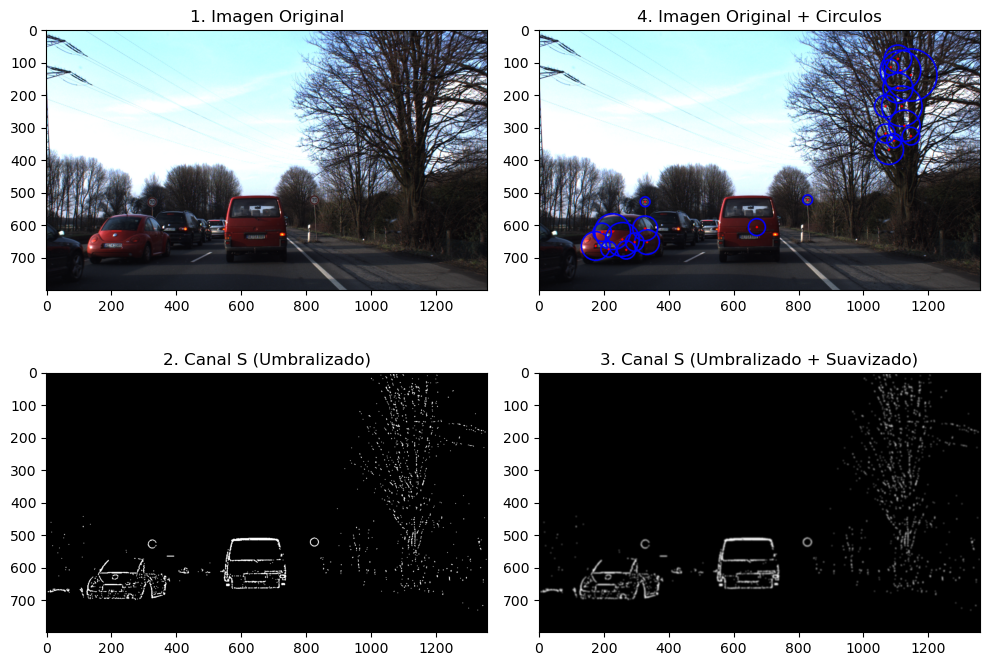

In [75]:
# Colocar ruta de la imagen a probar
ruta = "./imagenes/00009.ppm"

# Parametros de la funcion de binarización
vecindad_umbralizacion = 5
kernel_size_suavizado = 9
sigmax_suavizado = 2
limpiar_ruido = True

# Parametros de la funcion de detección de círculos
agrupacion = 1
distMin = 30 
sensibilidad = 50 
votosMin = 30 
radioMin = 10 
radioMax = 100

img,H,S,V = importar_imagen_y_HSV(ruta)
S_bin, S_bin_suavizado = binarizar_canal(S,H, vecindad_umbralizacion, kernel_size_suavizado, sigmax_suavizado, limpiar_ruido)
circulos,img_resultante = detectar_circulos(img, S_bin_suavizado, agrupacion, distMin, sensibilidad, votosMin, radioMin, radioMax)

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.title("1. Imagen Original")
# Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)) 

plt.subplot(2, 2, 3)
plt.title("2. Canal S (Umbralizado)")
plt.imshow(S_bin, cmap="gray")

plt.subplot(2, 2, 4)
plt.title("3. Canal S (Umbralizado + Suavizado)")
plt.imshow(S_bin_suavizado, cmap="gray")

plt.subplot(2, 2, 2)
plt.title("4. Imagen Original + Circulos")
# Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
plt.imshow(cv.cvtColor(img_resultante, cv.COLOR_BGR2RGB)) 
plt.tight_layout()
plt.show()

# Módulo de Validación de Candidatos

**Función:** filtra las falsas alarmas del detector de círculos y prepara cada señal confirmada para la CNN.

```
Detector  ──►  validar_candidatos()  ──►  Clasificador CNN
  img BGR + círculos       parches 60x60 grises      lee resultados["parches_cnn"]
```

**Entrada** (tal cual la entrega el detector, sin adaptar nada):
- `img_bgr`: imagen cargada con OpenCV (BGR).
- `circulos`: salida de `detectar_circulos` (array `uint16` de forma `(1, N, 3)`, o `None`).

**Salida** (`dict`) — para el módulo de la CNN:
- `parches_cnn`: lista de imágenes `(60, 60)` `uint8` en escala de grises, una por señal confirmada.
- `detecciones_validas`: lista de `(cx, cy, radio)` de la escena, **en el mismo orden** que `parches_cnn`.
- `falsas_alarmas`: lista de `(cx, cy, radio)` descartados.

**Pasos por candidato:** corregir radio → recortar ROI → máscara acromática (CAD) → comprobar círculo blanco interior concéntrico → gris 60×60 (ITU-R BT.601).

**Dependencias del archivo conjunto:** las funciones de Antonio `importar_imagen_y_HSV`, `binarizar_canal` y `detectar_circulos` (solo las usa `probar_validacion`).

## Parámetros

In [76]:
D_CAD = 30.0                  # escala acromática del índice CAD (rango válido 10-30; el artículo usa 19)
TAM_CNN = (60, 60)            # tamaño de entrada de la CNN
MARGEN_ROI = 0.10             # margen sobre el radio al recortar la señal
RADIO_MIN, RADIO_MAX = 8, 60  # radio exterior admitido para una señal (px)
ANILLO_PICO_MIN = 0.50        # fracción mínima de rojo en el pico del anillo
ANILLO_RATIO = (0.50, 0.95)   # rango de (radio interior / radio exterior) del anillo
FRAC_INTERIOR = 0.85          # el interior se mide dentro de 0.85 * radio interior
ACROMATICO_MIN = 0.30         # fracción mínima de píxeles acromáticos en el interior
ROJO_MAX = 0.35               # fracción máxima de píxeles rojos en el interior (el camión/coche rojo de las clases 9 y 10 ocupa hasta ~0.3)
COBERTURA_MIN = 0.75          # fracción mínima de la circunferencia del anillo que debe ser roja
BRILLO_MIN = 1.2              # el interior debe ser al menos 1.2 veces más brillante (gris) que el rojo del anillo

## Funciones de validación

In [77]:
def normalizar_candidatos(circulos):
    """Convierte la salida del detector ((1,N,3) uint16, (N,3), lista de tuplas o None)
    en una lista de (cx, cy, radio) enteros de Python. Se pasa a float antes de
    convertir porque con uint16 una resta como cx - lado daría la vuelta."""
    if circulos is None:
        return []
    arr = np.asarray(circulos, dtype=np.float64).reshape(-1, 3)
    return [tuple(int(round(v)) for v in c) for c in arr]


def recortar_roi(img_rgb, cx, cy, radio, margen=MARGEN_ROI):
    """Recorta la ROI cuadrada alrededor del círculo, sin salirse de la imagen.
    Devuelve la ROI y la esquina (x1, y1) del recorte en la escena."""
    lado = int(np.ceil(radio * (1 + margen)))
    alto, ancho = img_rgb.shape[:2]
    x1, y1 = max(0, cx - lado), max(0, cy - lado)
    x2, y2 = min(ancho, cx + lado), min(alto, cy + lado)
    return img_rgb[y1:y2, x1:x2], (x1, y1)


def mascara_roja(roi_rgb):
    """Máscara booleana de píxeles rojos (mismo criterio de H y S que el detector)."""
    hsv = cv.cvtColor(roi_rgb, cv.COLOR_RGB2HSV)
    tono = hsv[:, :, 0].astype(np.float32)               # H en [0, 179]
    return ((tono >= 179 * 0.8) | (tono <= 179 * 0.1)) & (hsv[:, :, 1] >= 0.3 * 255)


def mascara_acromatica(roi_rgb, D=D_CAD):
    """Máscara (255 = blanco/gris/negro) con el índice CAD < 1:
    CAD = (|R-G| + |G-B| + |B-R|) / (3*D). D debe estar entre 10 y 30."""
    if not 10 <= D <= 30:
        raise ValueError("D debe estar entre 10 y 30")
    r, g, b = (roi_rgb[:, :, i].astype(np.float32) for i in range(3))   # float: evita desbordar uint8
    cad = (np.abs(r - g) + np.abs(g - b) + np.abs(b - r)) / (3.0 * D)
    mascara = (cad < 1.0).astype(np.uint8) * 255
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
    return cv.morphologyEx(mascara, cv.MORPH_OPEN, kernel)          # quita ruido aislado


def medir_anillo(img_rgb, cx, cy, radio):
    """Mide el anillo rojo alrededor de (cx, cy) con el perfil radial: fracción de rojo
    en cada distancia al centro, promediada en 72 ángulos. El anillo es el pico del perfil;
    sus bordes están donde el perfil cae a la mitad del pico.
    Devuelve (pico, r_interior, r_exterior), o (pico, 0, 0) si el anillo no está bien definido.
    No depende de que `radio` sea exacto: busca entre 0.5 y 1.9 veces ese valor."""
    roi, (x1, y1) = recortar_roi(img_rgb, cx, cy, radio, margen=1.9)
    if roi.size == 0:
        return 0.0, 0, 0
    rojo = mascara_roja(roi)
    angulos = np.linspace(0, 2 * np.pi, 72, endpoint=False)
    dist = np.arange(max(3, int(0.5 * radio)), int(1.9 * radio) + 1)          # distancias al centro (px)
    xs = np.rint(cx - x1 + np.outer(dist, np.cos(angulos))).astype(int)
    ys = np.rint(cy - y1 + np.outer(dist, np.sin(angulos))).astype(int)
    dentro = (xs >= 0) & (xs < roi.shape[1]) & (ys >= 0) & (ys < roi.shape[0])
    es_rojo = np.where(dentro, rojo[np.clip(ys, 0, roi.shape[0] - 1), np.clip(xs, 0, roi.shape[1] - 1)], False)

    valido = dentro.sum(axis=1) >= 0.5 * len(angulos)       # distancias con la mitad de la circunferencia dentro de la imagen
    if valido.sum() < 4:
        return 0.0, 0, 0
    perfil = np.where(valido, es_rojo.sum(axis=1) / np.maximum(dentro.sum(axis=1), 1), 0.0)
    perfil = np.convolve(perfil, np.ones(3) / 3, mode="same")                 # suavizado

    k = int(np.argmax(perfil))
    pico = float(perfil[k])
    if pico < 0.2:
        return pico, 0, 0
    i = k
    while i > 0 and perfil[i] >= 0.5 * pico:                # borde interior: baja hasta la mitad del pico
        i -= 1
    o = k
    while o < len(perfil) - 1 and perfil[o] >= 0.5 * pico:  # borde exterior
        o += 1
    if perfil[i] >= 0.5 * pico or perfil[o] >= 0.5 * pico:  # el rojo no termina (disco macizo, fondo rojo)
        return pico, 0, 0
    return pico, int(dist[i]), int(dist[o])


def anillo_completo(roi_rgb, r_int, r_ext, centro):
    """True si el rojo rodea la señal: al menos COBERTURA_MIN de los 72 ángulos tiene rojo
    (en alguno de los 3 radios centrales del anillo). Descarta fragmentos rojos con forma de arco."""
    rojo = mascara_roja(roi_rgb)
    angulos = np.linspace(0, 2 * np.pi, 72, endpoint=False)
    con_rojo = np.zeros(len(angulos), dtype=bool)
    for radio in (0.5 * (r_int + r_ext) + d for d in (-1, 0, 1)):
        xs = np.rint(centro[0] + radio * np.cos(angulos)).astype(int)
        ys = np.rint(centro[1] + radio * np.sin(angulos)).astype(int)
        dentro = (xs >= 0) & (xs < rojo.shape[1]) & (ys >= 0) & (ys < rojo.shape[0])
        con_rojo |= dentro & rojo[np.clip(ys, 0, rojo.shape[0] - 1), np.clip(xs, 0, rojo.shape[1] - 1)]
    return con_rojo.mean() >= COBERTURA_MIN


def interior_valido(roi_rgb, r_int, r_ext, centro):
    """True si el interior de la señal parece un fondo blanco: mayoritariamente acromático,
    con poco rojo y claramente más brillante que el anillo rojo (esto último no depende de la
    iluminación: un blanco en penumbra sigue siendo más claro que el rojo de su anillo).
    `centro` = (x, y) del candidato dentro de la ROI."""
    if min(roi_rgb.shape[:2]) < 10:
        return False
    yy, xx = np.mgrid[:roi_rgb.shape[0], :roi_rgb.shape[1]]
    dist = np.hypot(xx - centro[0], yy - centro[1])
    interior = dist <= max(2, FRAC_INTERIOR * r_int)
    anillo = (dist >= r_int) & (dist <= r_ext)
    rojo = mascara_roja(roi_rgb)
    anillo_rojo = anillo & rojo
    if not anillo_rojo.any():
        return False
    gris = 0.299 * roi_rgb[:, :, 0] + 0.587 * roi_rgb[:, :, 1] + 0.114 * roi_rgb[:, :, 2]
    acromatico = (mascara_acromatica(roi_rgb)[interior] > 0).mean()
    brillo = gris[interior].mean() / max(gris[anillo_rojo].mean(), 1e-6)
    return (acromatico >= ACROMATICO_MIN and rojo[interior].mean() <= ROJO_MAX
            and brillo >= BRILLO_MIN)


def preprocesar_para_cnn(roi_rgb, normalizar=False):
    """ROI -> 60x60 en gris con Y = 0.299 R + 0.587 G + 0.114 B (ITU-R BT.601).
    Devuelve uint8 [0, 255], o float32 [0, 1] si normalizar=True."""
    roi = cv.resize(roi_rgb, TAM_CNN, interpolation=cv.INTER_LINEAR).astype(np.float32)
    gris = 0.299 * roi[:, :, 0] + 0.587 * roi[:, :, 1] + 0.114 * roi[:, :, 2]
    return (gris / 255.0).astype(np.float32) if normalizar else np.round(gris).astype(np.uint8)


def validar_candidatos(img_bgr, circulos, normalizar=False):
    """Función principal del módulo. Recibe la imagen BGR y los círculos del detector
    y devuelve {'parches_cnn', 'detecciones_validas', 'falsas_alarmas'}.
    parches_cnn[i] corresponde a detecciones_validas[i]."""
    img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
    parches, validas, falsas = [], [], []

    for cx, cy, radio in normalizar_candidatos(circulos):
        pico, r_int, r_ext = medir_anillo(img_rgb, cx, cy, radio)
        anillo_ok = (pico >= ANILLO_PICO_MIN and RADIO_MIN <= r_ext <= RADIO_MAX
                     and r_ext > 0 and ANILLO_RATIO[0] <= r_int / r_ext <= ANILLO_RATIO[1])
        if anillo_ok:
            roi, (x1, y1) = recortar_roi(img_rgb, cx, cy, r_ext)
            centro = (cx - x1, cy - y1)
            if roi.size and anillo_completo(roi, r_int, r_ext, centro) and interior_valido(roi, r_int, r_ext, centro):
                if any(np.hypot(cx - vx, cy - vy) < 0.5 * max(r_ext, vr) for vx, vy, vr in validas):
                    continue                           # misma señal ya confirmada (p. ej. detectada a dos escalas)
                parches.append(preprocesar_para_cnn(roi, normalizar))
                validas.append((cx, cy, r_ext))        # radio exterior real, no el del detector
                continue
        falsas.append((cx, cy, radio))

    return {"parches_cnn": parches, "detecciones_validas": validas, "falsas_alarmas": falsas}

## Detección a dos escalas (opcional, sin modificar el código de Antonio)
El detector de Antonio rara vez encuentra las señales pequeñas (diámetro < 30 px): el círculo apenas reúne votos en el acumulador de Hough. Si se **amplía la imagen ×2** y se vuelve a ejecutar *el mismo* detector, esas señales pasan a tener un radio de 16-30 px y sí se detectan. `detectar_candidatos` hace las dos pasadas (escala original y ×2), devuelve los círculos en coordenadas de la imagen original y con el mismo formato que `detectar_circulos` (`(1, N, 3)` `uint16`), así que se puede pasar tal cual a `validar_candidatos`, que además elimina los duplicados entre pasadas.

Cada pasada es `(ampliación, radioMin, radioMax)` con los radios medidos en la imagen ya ampliada. Como `importar_imagen_y_HSV` solo acepta una ruta, la imagen ampliada se guarda en un archivo temporal; si Antonio añadiera una versión que acepte un array, ese archivo ya no haría falta.

In [78]:
PASADAS_DETECTOR = [(1, 8, 60),     # escala original: señales de radio 8-60 px
                    (2, 16, 60)]    # imagen ×2: señales de radio 8-30 px (las pequeñas)


def detectar_candidatos(ruta_imagen, pasadas=PASADAS_DETECTOR):
    """Ejecuta el detector de Antonio en cada pasada y junta los círculos (escala original primero).
    Parámetros de Antonio: los de su celda de ejemplo (binarizado 5, 9, 2, True; Hough 1, 30, 50, 30).
    Devuelve (img_bgr, circulos): circulos es un array uint16 (1, N, 3), o None si no hay ninguno."""
    img_bgr = cv.imread(ruta_imagen)
    if img_bgr is None:
        raise FileNotFoundError(f"No se pudo cargar la imagen: {ruta_imagen}")
    todos = []
    with tempfile.TemporaryDirectory() as carpeta:
        for k, radio_min, radio_max in pasadas:
            ruta = ruta_imagen
            if k != 1:
                ruta = os.path.join(carpeta, "ampliada.png")
                cv.imwrite(ruta, cv.resize(img_bgr, None, fx=k, fy=k, interpolation=cv.INTER_CUBIC))
            _, H, S, _ = importar_imagen_y_HSV(ruta)
            _, S_suave = binarizar_canal(S, H, 5, 9, 2, True)
            circulos, _ = detectar_circulos(img_bgr, S_suave, 1, 30, 50, 30, radio_min, radio_max)
            if circulos is not None:
                todos += [(int(round(x / k)), int(round(y / k)), int(round(r / k))) for x, y, r in circulos[0].astype(float)]
    return img_bgr, (np.array([todos], dtype=np.uint16) if todos else None)

## Prueba rápida
`probar_validacion(ruta)` ejecuta el detector de Antonio y este módulo sobre una imagen, y muestra la escena (verde = señal, rojo = falsa alarma) y los parches que recibirá la CNN.
También se puede probar sin el detector pasando candidatos a mano: `probar_validacion(ruta, circulos=[(cx, cy, r)])`.


In [79]:
def probar_validacion(ruta_imagen, circulos=None, max_parches=12):
    """Prueba rápida del módulo sobre una imagen (.ppm, .jpg, .png...).
    Sin `circulos` usa `detectar_candidatos` (detector de Antonio a dos escalas; sus funciones deben estar definidas)."""
    if circulos is None:
        img_bgr, circulos = detectar_candidatos(ruta_imagen)
    else:
        img_bgr = cv.imread(ruta_imagen)
        if img_bgr is None:
            raise FileNotFoundError(f"No se pudo cargar la imagen: {ruta_imagen}")

    res = validar_candidatos(img_bgr, circulos)
    print(f"Candidatos: {len(normalizar_candidatos(circulos))} | "
          f"señales confirmadas: {len(res['detecciones_validas'])} | "
          f"falsas alarmas: {len(res['falsas_alarmas'])}")

    plt.figure(figsize=(9, 5))
    plt.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    for cx, cy, r in res["falsas_alarmas"]:
        plt.gca().add_patch(plt.Circle((cx, cy), r, fill=False, color="red", lw=0.8, ls="--"))
    for cx, cy, r in res["detecciones_validas"]:
        plt.gca().add_patch(plt.Circle((cx, cy), r, fill=False, color="lime", lw=2))
    plt.title("Verde: señal confirmada | Rojo: falsa alarma")
    plt.axis("off")
    plt.show()

    n = min(len(res["parches_cnn"]), max_parches)
    if n:
        fig, ejes = plt.subplots(1, n, figsize=(1.8 * n, 2.2), squeeze=False)
        for ax, parche, det in zip(ejes[0], res["parches_cnn"], res["detecciones_validas"]):
            ax.imshow(parche, cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"({det[0]}, {det[1]})", fontsize=8)
            ax.axis("off")
        fig.suptitle("Parches 60x60 para la CNN")
        plt.show()
    return res

In [80]:
# Ejemplos de uso (descomentar):

resultados = probar_validacion("imagenes/00009.ppm")   # con el detector de Antonio

detectadas = resultados["parches_cnn"]
# resultados = probar_validacion("banco/00009.ppm", circulos=[(150, 200, 32)])  # candidatos a mano

NameError: name 'tempfile' is not defined

## Uso desde el archivo conjunto
Tras la celda del detector (variables `img` y `circulos` de Antonio), el módulo se llama así, y la salida queda disponible para el módulo de la CNN:


In [81]:
# Opción A: detector a dos escalas (recomendado)
img, circulos = detectar_candidatos("imagenes/00009.ppm")
# Opción B: los círculos que ya da la celda de Antonio (una sola escala)
resultados = validar_candidatos(img, circulos)
#
parches_cnn = resultados["parches_cnn"]                  # lista de (60, 60) uint8 -> entrada de la CNN
detecciones_validas = resultados["detecciones_validas"]  # (cx, cy, radio) de cada parche, mismo orden
lote_cnn = np.array(parches_cnn)[..., np.newaxis]        # (N, 60, 60, 1) si la CNN espera lote con canal

NameError: name 'tempfile' is not defined

# Módulo de clasificación de señales (CNN)

## Sección 1: Configuracion

In [82]:
torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


### Razón de la configuración inicial

Las semillas aleatorias se fijan para que las operaciones que dependen del azar, como la inicialización de los pesos o la selección de las secuencias de validación, produzcan resultados reproducibles. Esto permite comparar distintas ejecuciones sabiendo que no han cambiado los datos de partida.

`device` selecciona automáticamente la GPU si PyTorch encuentra una disponible y, en caso contrario, utiliza la CPU. El modelo y los lotes de imágenes deben estar siempre en el mismo dispositivo; por eso más adelante se usa `.to(device)` tanto para la red como para los datos.

## Seccion 2: Datos

In [83]:
RUTA = Path("../Datasets/GTSRB/")
train = pd.read_csv(RUTA / "Train.csv")
print(train.shape)
train.head()

(39209, 8)


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


* Path("archive") crea un objeto de ruta. Con pathlib, el operador / une partes de la ruta y funciona igual en Windows, Mac y Linux, sin preocuparte por las barras.
* pd.read_csv(...) lee el archivo y lo convierte en una tabla.

Filtramos los datos con las 12 clases que tenemos, segun el articulo deberian ser 17310.

In [84]:
PROHIBICION = [0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 15, 16]
train12 = train[train["ClassId"].isin(PROHIBICION)].copy()
print(len(train12))
train12.head()

17310


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
360,29,30,5,6,24,25,0,Train/0/00000_00000_00000.png
361,30,30,5,5,25,25,0,Train/0/00000_00000_00001.png
362,30,30,5,5,25,25,0,Train/0/00000_00000_00002.png
363,31,31,5,5,26,26,0,Train/0/00000_00000_00003.png
364,30,32,5,6,25,26,0,Train/0/00000_00000_00004.png


### Por qué se filtran las clases

GTSRB contiene más clases de señales, pero el trabajo se centra en el subconjunto de señales de prohibición indicado en el artículo. `isin(PROHIBICION)` genera una condición booleana que conserva únicamente las filas cuyo `ClassId` pertenece a esa lista. Se usa `.copy()` para crear una tabla independiente y evitar modificaciones accidentales sobre el `DataFrame` original.

El modelo se construye con 12 salidas porque solo debe distinguir estas 12 clases. Posteriormente se crea una etiqueta interna entre 0 y 11, ya que las clases originales no son consecutivas.

In [85]:
ruta_img = RUTA / train12.iloc[0]["Path"]
print(ruta_img)
print(ruta_img.exists())

..\Datasets\GTSRB\Train\0\00000_00000_00000.png
True


In [86]:
def a_tensor(recortes):
    """recortes: array uint8 de forma (N, 60, 60), valores 0-255."""
    assert recortes.dtype == np.uint8, "Se esperaba uint8 (0-255)"
    assert recortes.ndim == 3 and recortes.shape[1:] == (60, 60), "Se esperaba (N, 60, 60)"
    x = torch.from_numpy(recortes).float() / 255.0   # a decimales entre 0 y 1
    x = x.unsqueeze(1)                               # añade el canal: (N, 1, 60, 60)
    return x



* torch.from_numpy(recortes) convierte el array de NumPy en un tensor de PyTorch (comparten memoria, no se copia).
* .float() pasa de uint8 a float32. Esto va antes de dividir, que es lo importante.
* / 255.0 lleva el rango de 0-255 a 0-1.
* .unsqueeze(1) inserta el eje de canales en la posición 1. Una imagen gris suele tener forma (60, 60), sin canal, y la convolución espera (N, 1, 60, 60)

In [87]:
prueba = np.random.randint(0, 256, size=(4, 60, 60), dtype=np.uint8)
x = a_tensor(prueba)
print(x.shape, x.dtype, x.min().item(), x.max().item())

torch.Size([4, 1, 60, 60]) torch.float32 0.0 1.0


* np.random.randint(0, 256, ...) genera números enteros al azar. El límite superior (256) no se incluye, así que salen valores de 0 a 255, el rango de una imagen de 8 bits.
* size=(4, 60, 60) es la forma del array: 4 imágenes de 60×60 píxeles. Sin canal, porque así acordamos que las entrega Alberto.
* dtype=np.uint8 fija el tipo: entero sin signo de 8 bits, igual que el que da OpenCV
* x.shape es la forma del tensor
* x.dtype es el tipo de dato.
* x.min() y x.max() devuelven el valor mínimo y el máximo. Son tensores de un solo elemento.
* .item() extrae ese elemento como un número normal de Python, para que se imprima limpio.
* bloque(x) ejecuta en orden las cuatro capas: convolución, BN, ReLU y max pooling. PyTorch permite llamar al modelo como si fuera una función.
* .shape da el tamaño de lo que sale.
* bloque.parameters() recorre todos los parámetros que la red aprende: pesos y sesgos de la convolución, y γ y β de la BN.
* p.numel() cuenta cuántos números contiene cada uno. 8 filtros; el padding conserva 60×60 y el pooling lo reduce a 30×30
* sum(...) los suma todos. Conv: 8·(3·3·1) + 8 = 80. BN: 8 γ + 8 β = 16

In [88]:
nombre = train12["Path"].str.split("/").str[-1]
train12["Secuencia"] = nombre.str.split("_").str[1]
train12["IdSecuencia"] = train12["ClassId"].astype(str) + "_" + train12["Secuencia"]

print(train12["IdSecuencia"].nunique())
print(train12.groupby("IdSecuencia").size().describe())

577
count    577.0
mean      30.0
std        0.0
min       30.0
25%       30.0
50%       30.0
75%       30.0
max       30.0
dtype: float64


- train12["Path"] es la columna con rutas como Train/20/00020_00000_00000.png.
- .str.split("/") parte cada ruta por las barras y da una lista: ["Train", "20", "00020_00000_00000.png"].
- .str[-1] se queda con el último elemento de cada lista, es decir, el nombre del archivo.
- .str.split("_") parte el nombre por los guiones bajos: ["00020", "00000", "00000.png"].
- .str[1] toma el elemento de la posición 1, que es el segundo: el número de secuencia ("00000"). Se empieza a contar en 0, por eso es el 1 y no el 2.
- El resultado se guarda como una columna nueva.
- ClassId es un número y Secuencia es texto. Para poder unirlos con +, primero se pasa ClassId a texto con .astype(str).
- Se unen con un guion bajo en medio. Ejemplo: clase 16 y secuencia 00003 dan "16_00003".
- El número de secuencia se repite entre clases (todas tienen su 00000), pero la pareja clase + secuencia no.
- .nunique() cuenta los valores distintos de la columna.
- .groupby("IdSecuencia") agrupa las filas que comparten identificador.
- .size() cuenta cuántas filas tiene cada grupo.
- .describe() resume esas cuentas: cuántos grupos hay, la media, el mínimo y el máximo.

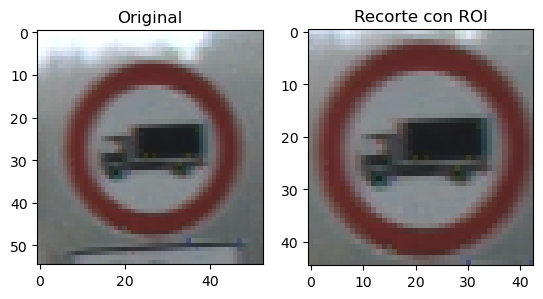

In [89]:
fila = train12[train12["ClassId"] == 16].iloc[0]
img = cv.imread(str(RUTA / fila["Path"]))
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
x1, y1, x2, y2 = fila["Roi.X1"], fila["Roi.Y1"], fila["Roi.X2"], fila["Roi.Y2"]
recorte = img[y1:y2, x1:x2]

fig, ejes = plt.subplots(1, 2)
ejes[0].imshow(img);     ejes[0].set_title("Original")
ejes[1].imshow(recorte); ejes[1].set_title("Recorte con ROI")
plt.show()

### Comprobación visual de la región de interés

Esta celda se utiliza para comprobar que las coordenadas de la región de interés (ROI) del archivo CSV delimitan correctamente la señal antes de comenzar el preprocesamiento y el entrenamiento. Se selecciona una imagen de la clase 16 como ejemplo, aunque el mismo procedimiento se aplica a todas las imágenes del conjunto.

Primero se lee la imagen original con OpenCV. Como OpenCV utiliza el orden de canales BGR y Matplotlib espera RGB, se cambia el orden con `cv.cvtColor`; de lo contrario, los colores se mostrarían incorrectamente. Después se extraen las coordenadas `Roi.X1`, `Roi.Y1`, `Roi.X2` y `Roi.Y2` y se recorta la imagen mediante `img[y1:y2, x1:x2]`. En NumPy se indican primero las filas, que corresponden al eje vertical `y`, y después las columnas, que corresponden al eje horizontal `x`.

Finalmente se muestran la imagen completa y el recorte lado a lado. Esta comparación permite detectar errores en las coordenadas, comprobar que la señal no queda cortada y verificar que el recorte contiene principalmente la señal. Es importante porque la CNN no recibe la imagen completa, sino este recorte como entrada.

- str(RUTA / ...): OpenCV espera una cadena de texto, no un objeto Path.
- cv.imread devuelve None sin avisar si no encuentra el archivo. Por eso conviene comprobar img is not None.
- cv.cvtColor(..., BGR2RGB): OpenCV carga en BGR, y matplotlib espera RGB. Sin esta línea, los colores salen cambiados.
- img[y1:y2, x1:x2]: primero filas (y), luego columnas (x).
- plt.subplots(1, 2) crea una figura con dos imágenes lado a lado.

In [90]:
def cargar_recorte(fila, ruta=RUTA):
    # 1. Lee la imagen (OpenCV la carga en BGR)
    img = cv.imread(str(ruta / fila["Path"]))
    assert img is not None, f"No se pudo leer {fila['Path']}"
    # 2. Recorta con el ROI (filas y1:y2, columnas x1:x2)
    x1, y1, x2, y2 = fila["Roi.X1"], fila["Roi.Y1"], fila["Roi.X2"], fila["Roi.Y2"]
    recorte = img[y1:y2, x1:x2]
    # 3. Pasa a gris (BGR2GRAY, porque OpenCV carga en BGR)
    gris = cv.cvtColor(recorte, cv.COLOR_BGR2GRAY)
    # 4. Redimensiona a 60x60
    recorte_final = cv.resize(gris, (60, 60), interpolation=cv.INTER_LINEAR)
    return recorte_final     # forma (60, 60), dtype uint8

- cv.resize recibe (ancho, alto), no (alto, ancho). En un cuadrado no se nota, pero hay que saberlo.
- La interpolación importa: cv.INTER_AREA suele ir mejor al reducir y cv.INTER_LINEAR o INTER_CUBIC al ampliar. Como casi todas las imágenes de GTSRB miden menos de 60 píxeles (la media ronda los 46), la mayoría se amplía. El artículo no especifica el método, así que es una decisión vuestra que debéis acordar con Alberto y documentar. Debe ser la misma para entrenamiento y para inferencia.
- cv.COLOR_BGR2GRAY aplica los pesos de luminancia 0,299/0,587/0,114 de la ecuación del artículo, y trata correctamente el orden BGR de OpenCV.

### Razón de la función `cargar_recorte`

La función concentra en un único lugar todo el preprocesamiento que debe recibir cada imagen antes de entrar en la CNN. Recibe una fila del CSV, porque esa fila contiene tanto la ruta del archivo como las coordenadas de la señal. El parámetro `ruta=RUTA` permite reutilizar la función con otra carpeta sin cambiar su código.

El `assert` detiene la ejecución si la imagen no se ha podido leer; es preferible detectar el problema en ese punto que entrenar silenciosamente con datos faltantes. Después se recorta la señal, se pasa a escala de grises para que coincida con la entrada de un canal definida en la red y se redimensiona a 60 × 60 para que todas las imágenes tengan exactamente la misma forma. La función devuelve un array `uint8`, manteniendo inicialmente el formato de imagen de OpenCV. La normalización y la incorporación del canal se hacen más adelante con `a_tensor`.

(60, 60) uint8


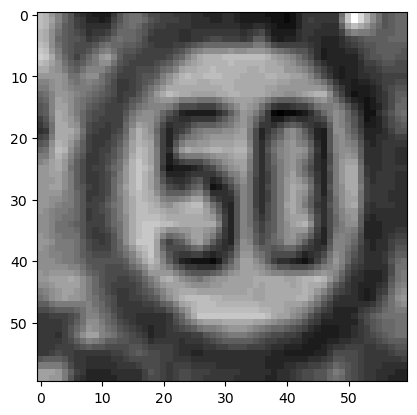

torch.Size([1, 1, 60, 60])


In [91]:
fila = train12[train12["ClassId"] == 2].iloc[0]
r = cargar_recorte(fila)
print(r.shape, r.dtype)
plt.imshow(r, cmap="gray"); plt.show()

x = a_tensor(r[np.newaxis, ...])
print(x.shape)

### Comprobación del formato de entrada

Se selecciona una imagen de la clase 2 para probar la cadena completa de preprocesamiento antes de utilizarla con todo el conjunto. Primero se comprueba que `cargar_recorte` devuelve una imagen de forma `(60, 60)` y tipo `uint8`, que es el formato esperado por `a_tensor`. La visualización en escala de grises permite comprobar que el recorte sigue siendo reconocible después de convertirlo desde color.

`r[np.newaxis, ...]` añade una dimensión al principio para representar un lote de una sola imagen. Por eso `a_tensor` devuelve finalmente un tensor con forma `(1, 1, 60, 60)`: un ejemplo, un canal y las dimensiones espaciales de 60 × 60. Esta prueba sirve para confirmar que una imagen individual puede recorrer el mismo camino que se utilizará durante el entrenamiento.

In [92]:
rng = np.random.default_rng(0)
ids_val = []

for clase, grupo in train12.groupby("ClassId"):
    ids = grupo["IdSecuencia"].unique()
    n_val = max(1, round(0.2 * len(ids)))
    ids_val += list(rng.choice(ids, size=n_val, replace=False))

train12["EsVal"] = train12["IdSecuencia"].isin(ids_val)

### Por qué la validación se separa por secuencias

El objetivo de este código es crear un conjunto de validación representativo sin separar fotografías pertenecientes a la misma secuencia. Las imágenes de una secuencia suelen ser muy parecidas, por lo que repartirlas individualmente podría hacer que la red reconociera características casi idénticas en entrenamiento y validación y produjera una precisión artificialmente alta.

Se recorre cada clase por separado para realizar un reparto estratificado: aproximadamente el 20 % de sus secuencias se reserva para validar. `replace=False` evita elegir dos veces la misma secuencia y `max(1, ...)` garantiza que incluso una clase pequeña tenga al menos una secuencia de validación. Finalmente, `isin(ids_val)` marca todas las imágenes de las secuencias elegidas. Así, si una secuencia contiene 30 imágenes, las 30 pasan juntas a validación o las 30 permanecen en entrenamiento.

- rng = np.random.default_rng(0): generador de números aleatorios con semilla fija, para que el reparto sea el mismo cada vez que ejecutes el notebook (y el mismo para los tres del grupo).
- groupby("ClassId"): recorre las clases de una en una. Se reparte dentro de cada clase (reparto estratificado) para que todas aparezcan en validación. Si repartieras todas las secuencias juntas, una clase pequeña como la 0 (7 secuencias) podría quedarse sin ninguna en validación por mala suerte.
- grupo["IdSecuencia"].unique(): las secuencias distintas de esa clase.
- n_val = max(1, round(0.2 * len(ids))): el 20 % de las secuencias, con un mínimo de 1. Con la clase 0 (7 secuencias), el 20 % da 1,4 y se redondea a 1.
- rng.choice(ids, size=n_val, replace=False): elige al azar n_val secuencias sin repetir (replace=False).
- ids_val += ...: acumula las secuencias elegidas.
- isin(ids_val): marca como True en EsVal todas las imágenes cuya secuencia fue elegida. Así las 30 fotos de una secuencia van siempre juntas

In [93]:
class_a_indice = {c: i for i, c in enumerate(PROHIBICION)}
train12["Etiqueta"] = train12["ClassId"].map(class_a_indice)

### Conversión de las etiquetas

La red no utiliza directamente los identificadores originales de GTSRB como posiciones de salida. Se crea el diccionario `class_a_indice`, que relaciona cada `ClassId` con una posición consecutiva dentro de las 12 clases seleccionadas.

Esto es necesario porque la salida de la CNN tiene 12 neuronas y `CrossEntropyLoss` espera etiquetas enteras en el intervalo `[0, 11]`. La conversión inversa se realiza con `PROHIBICION[prediccion]` al mostrar los resultados.

In [94]:
val = train12[train12["EsVal"]]
ent = train12[~train12["EsVal"]]
print(len(ent), len(val), round(len(val) / len(train12), 3))

assert set(ent["IdSecuencia"]).isdisjoint(set(val["IdSecuencia"]))

13890 3420 0.198


- train12["EsVal"] es una columna de True y False: True si la imagen pertenece a una secuencia elegida para validación.
- Usar esa columna dentro de los corchetes filtra las filas: se queda solo con las que tienen True.
- val es una tabla con las imagenes de validacion
- ent es al reves, es una tabla con las imagenes de entrenamiento
- luego compruebo si hay el numero esperado de imagenes en val y ent y el porcentaje que es de validacion
- el assert comprueba que ninguna secuencia está a la vez en ent y en val

In [95]:
# Diagnóstico temporal: ¿existen en disco todas las imágenes que dice el CSV?
existe = pd.Series([(RUTA / p).exists() for p in train12["Path"]], index=train12.index)
print(existe.groupby(train12["ClassId"]).agg(["sum", "count"]))

          sum  count
ClassId             
0         210    210
1        2220   2220
2        2250   2250
3        1410   1410
4        1980   1980
5        1860   1860
7        1440   1440
8        1410   1410
9        1470   1470
10       2010   2010
15        630    630
16        420    420


In [96]:
def cargar_conjunto(tabla):
    X = np.stack([cargar_recorte(fila) for _, fila in tabla.iterrows()])
    y = tabla["Etiqueta"].to_numpy()
    return X, y

X_ent, y_ent = cargar_conjunto(ent)
X_val, y_val = cargar_conjunto(val)

### Construcción de los conjuntos de imágenes y etiquetas

`cargar_conjunto` recorre las filas de una tabla, aplica a cada una `cargar_recorte` y apila los recortes resultantes con `np.stack`. El resultado `X` es un único array con forma `(N, 60, 60)`, mientras que `y` contiene una etiqueta por imagen con forma `(N,)`. Mantener imágenes y etiquetas en el mismo orden es fundamental: la posición `i` de `X` debe corresponder a la posición `i` de `y`.

En este punto todavía se trabaja con arrays NumPy y valores enteros de 8 bits, porque es el formato natural de OpenCV. La conversión a tensores, normalización entre 0 y 1 y adición del canal se realiza después mediante `a_tensor`, justo antes de crear los lotes de PyTorch.

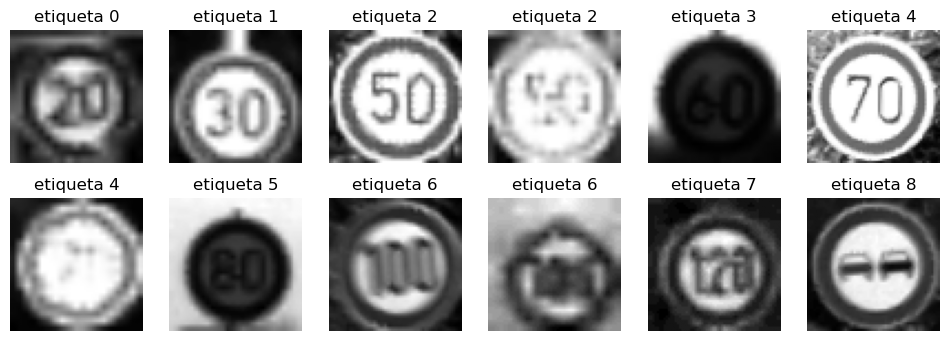

In [97]:
fig, ejes = plt.subplots(2, 6, figsize=(12, 4))
for i, ax in enumerate(ejes.flat):
    ax.imshow(X_ent[i * 1000], cmap="gray")
    ax.set_title(f"etiqueta {y_ent[i * 1000]}")
    ax.axis("off")
plt.show()

# Seccion 3: Modelo

In [98]:
bloque = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=20, kernel_size=21, padding=10),
    nn.BatchNorm2d(20),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
)

* in_channels=1: la imagen tiene 1 canal (gris).
* out_channels=20: la primera capa del artículo utiliza 20 filtros y produce 20 mapas de características.
* kernel_size=21: se utiliza 21×21 como variación experimental de la primera capa; el artículo especifica 20×20.
* padding=10: para un kernel de 21×21, añade 10 píxeles a cada lado y conserva el tamaño espacial de 60×60 antes del max pooling.
* El stride no lo pongo porque por defecto vale 1 (el filtro avanza de píxel en píxel).

In [99]:
x_prueba = a_tensor(np.random.randint(0, 256, size=(4, 60, 60), dtype=np.uint8))
print(bloque(x_prueba).shape)
print(sum(p.numel() for p in bloque.parameters()))

torch.Size([4, 20, 30, 30])
8880


In [100]:
def bloque_conv(c_in, c_out, kernel_size, pool=True):
    capas = [
        nn.Conv2d(c_in, c_out, kernel_size=kernel_size, padding=kernel_size // 2),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
    ]
    if pool:
        capas.append(nn.MaxPool2d(kernel_size=2))
    return nn.Sequential(*capas)


class CNNSenales(nn.Module):
    def __init__(self, n_clases=12, filtros=(20, 30, 40, 50), kernels=(21, 13, 9, 5)):
        super().__init__()
        f1, f2, f3, f4 = filtros
        k1, k2, k3, k4 = kernels
        self.features = nn.Sequential(
            bloque_conv(1, f1, k1),
            bloque_conv(f1, f2, k2),
            bloque_conv(f2, f3, k3),
            bloque_conv(f3, f4, k4, pool=False),   # la última convolución no lleva pooling
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(f4 * 7 * 7, n_clases),   # 60 -> 30 -> 15 -> 7 -> 7
        )

    def forward(self, x):
        return self.clasificador(self.features(x))

In [101]:
modelo = CNNSenales().to(device)

# Tamaño tras cada bloque
x = x_prueba.to(device)
for i, b in enumerate(modelo.features, start=1):
    x = b(x)
    print(f"bloque {i}:", tuple(x.shape))

# Salida completa y número de parámetros
salida = modelo(x_prueba.to(device))
print("salida:", tuple(salida.shape))
print("parámetros:", sum(p.numel() for p in modelo.parameters()))

# Con Softmax, las 12 probabilidades de cada imagen deben sumar 1
print(torch.softmax(salida, dim=1).sum(dim=1))

bloque 1: (4, 20, 30, 30)
bloque 2: (4, 30, 15, 15)
bloque 3: (4, 40, 7, 7)
bloque 4: (4, 50, 7, 7)
salida: (4, 12)
parámetros: 287252
tensor([1., 1., 1., 1.], device='cuda:0', grad_fn=<SumBackward1>)



## Razonamiento y explicación del código de la red completa

### Qué pide el artículo
Cuatro capas convolucionales, cada una seguida de normalización por lotes, activación y *pooling* (la última convolución **sin** *pooling*), y después una capa completamente conectada con Softmax y clasificación. La entrada es 60×60×1 y la salida son 12 clases.

### Decisiones de diseño
- **Una función `bloque_conv`:** los cuatro bloques repiten el patrón convolución → BN → ReLU → *pooling*. Escribirlo una vez evita errores de copia y pega. El parámetro `pool=False` permite construir el último bloque, que no reduce el tamaño.
- **Filtros 20, 30, 40 y 50:** corresponden a la red número 4 de la Tabla 3, que es la arquitectura de cuatro convoluciones con mejor precisión media del artículo.
- **Tamaños de kernel 21×21, 13×13, 9×9 y 5×5:** se utilizan kernels impares como variación propia para poder aplicar padding simétrico. Esta arquitectura ya no coincide exactamente con la Tabla 2 del artículo y debe evaluarse mediante un nuevo entrenamiento.
- **Tamaño tras cada bloque:** 60 → 30 → 15 → 7 → 7. El paso de 15 a 7 se debe a que el *pooling* 2×2 redondea hacia abajo (15/2 = 7,5). El último bloque no reduce, así que se queda en 7×7.
- **`Flatten` y `Linear`:** el último bloque produce 50 mapas de 7×7, es decir 50·7·7 = 2450 valores. `Flatten` los coloca en un vector y `Linear` los combina para dar 12 números, uno por clase. Si cambiáis los filtros o el *pooling*, hay que recalcular ese `7 * 7` (y `f4`).
- **La red no incluye Softmax:** la función de pérdida de PyTorch, `CrossEntropyLoss`, ya aplica internamente Softmax y logaritmo. Por eso la red devuelve los valores sin normalizar (*logits*). El Softmax se aplica solo cuando queremos probabilidades, como en la última línea de la prueba. Es equivalente a la capa Softmax más la capa de clasificación del artículo.

### Explicación de las líneas
- `nn.Module` es la clase base de los modelos en PyTorch. `super().__init__()` la inicializa, y sin esa línea PyTorch no registra las capas.
- `__init__` **declara** las capas. `forward` define **cómo pasan los datos** por ellas, y se ejecuta al llamar `modelo(x)`.
- `nn.Sequential(*capas)`: el asterisco desempaqueta la lista como argumentos separados.
- `self.features` agrupa los cuatro bloques y `self.clasificador` agrupa la parte final. Separarlos permite inspeccionar el tamaño tras cada bloque, como hace la prueba.
- `.to(device)` mueve los parámetros del modelo a CPU o GPU. Los datos tendrán que ir al mismo sitio.

### Qué comprueba la prueba y qué debe salir
- Tamaño tras cada bloque: `(4, 20, 30, 30)`, `(4, 30, 15, 15)`, `(4, 40, 7, 7)` y `(4, 50, 7, 7)`.
- Salida: `(4, 12)`, es decir, 12 valores por cada una de las 4 imágenes.
- Parámetros: **287 252** para esta variación experimental.
- La última línea debe mostrar cuatro valores iguales a 1 (con pequeños errores de redondeo).

### Dónde están los parámetros

| Parte | Parámetros |
|---|---|
| Bloque 1 (conv + BN) | 8 880 |
| Bloque 2 | 101 490 |
| Bloque 3 | 97 320 |
| Bloque 4 | 50 150 |
| Capa final (2450·12 + 12) | 29 412 |
| **Total** | **287 252** |

En esta arquitectura, el bloque 2 es el que concentra más parámetros debido a sus 30 filtros de 12×12. Los valores de media y varianza móviles de la BN no se cuentan porque no se aprenden por descenso de gradiente.

### Detalle para el entrenamiento y la evaluación
Con `modelo.train()` la BN usa las estadísticas del lote, y con `modelo.eval()` usa las acumuladas. Hay que activar `eval()` al medir la precisión y los tiempos de inferencia.

# Seccion 4: Entrenamiento

## Procedimiento de entrenamiento

El entrenamiento consiste en repetir un ciclo: seleccionar un lote de imágenes, calcular las predicciones de la CNN, medir el error respecto a las etiquetas conocidas, propagar ese error hacia atrás y actualizar los pesos. Una época equivale a recorrer una vez todas las imágenes del conjunto de entrenamiento.

Se mantiene separado el conjunto de validación para comprobar si la red generaliza a secuencias que no ha visto durante el ajuste de sus pesos. La validación no modifica el modelo; solo permite observar su comportamiento.

In [102]:
from torch.utils.data import TensorDataset, DataLoader

X_ent_t = a_tensor(X_ent);  y_ent_t = torch.from_numpy(y_ent).long()
X_val_t = a_tensor(X_val);  y_val_t = torch.from_numpy(y_val).long()

g = torch.Generator().manual_seed(0)
cargador_ent = DataLoader(TensorDataset(X_ent_t, y_ent_t), batch_size=64, shuffle=True, generator=g)
cargador_val = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=256, shuffle=False)

### Conversión a lotes

`TensorDataset` agrupa cada imagen con su etiqueta correspondiente. `DataLoader` utiliza ese conjunto para entregar los datos por lotes, en lugar de procesar todas las imágenes a la vez. El tamaño 64 para entrenamiento ofrece un equilibrio entre estabilidad de las actualizaciones y consumo de memoria; en validación se utiliza 256 porque allí no se calculan gradientes.

`shuffle=True` mezcla el orden de las muestras de entrenamiento en cada época para evitar que el modelo aprenda del orden de los datos. En validación se mantiene `shuffle=False`, ya que solo queremos medir y conservar un orden reproducible. El generador con semilla fija hace reproducible la mezcla.

In [103]:
torch.manual_seed(0)
modelo = CNNSenales().to(device)
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.01, momentum=0.9)

### Función de pérdida y optimizador

`CrossEntropyLoss` compara los logits producidos por la red con la etiqueta correcta. Combina internamente `LogSoftmax` y la pérdida de entropía cruzada, por lo que no se debe aplicar `Softmax` antes de calcular la pérdida.

El optimizador SGD modifica los pesos usando los gradientes calculados durante la retropropagación. La tasa de aprendizaje `lr=0.01` controla el tamaño de cada actualización y `momentum=0.9` acumula parte de la dirección de actualizaciones anteriores, ayudando a avanzar de forma más estable cuando el gradiente varía entre lotes.

In [104]:
def entrenar_epoca(modelo, cargador, criterio, optimizador):
    modelo.train()
    perdida_total, aciertos, n = 0.0, 0, 0
    for x, y in cargador:
        x, y = x.to(device), y.to(device)
        optimizador.zero_grad()
        salida = modelo(x)
        perdida = criterio(salida, y)
        perdida.backward()
        optimizador.step()

        perdida_total += perdida.item() * len(y)
        aciertos += (salida.argmax(dim=1) == y).sum().item()
        n += len(y)
    return perdida_total / n, aciertos / n


def evaluar(modelo, cargador, criterio):
    modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(device), y.to(device)
            salida = modelo(x)
            perdida_total += criterio(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            n += len(y)
    return perdida_total / n, aciertos / n

### Qué ocurre en `entrenar_epoca` y `evaluar`

En `entrenar_epoca`, `modelo.train()` activa el comportamiento de entrenamiento de capas como BatchNorm. Para cada lote se borran los gradientes anteriores, se calcula la salida, se obtiene la pérdida, se ejecuta `backward()` para calcular los gradientes y `step()` actualiza los pesos.

La pérdida y el número de aciertos se acumulan multiplicando la pérdida media del lote por su tamaño. Así, si el último lote tiene menos imágenes, no pesa igual que un lote completo al calcular la media final. `argmax(dim=1)` selecciona la salida de mayor valor como clase predicha.

`evaluar` sigue el mismo cálculo de pérdida y precisión, pero usa `modelo.eval()` y `torch.no_grad()`. No se llama a `backward()` ni al optimizador porque la validación solo mide el modelo y no debe modificarlo.

In [111]:
import time

N_EPOCAS = 2
historial = {"perdida_ent": [], "acc_ent": [], "perdida_val": [], "acc_val": []}

for epoca in range(1, N_EPOCAS + 1):
    t0 = time.time()
    p_ent, a_ent = entrenar_epoca(modelo, cargador_ent, criterio, optimizador)
    p_val, a_val = evaluar(modelo, cargador_val, criterio)
    for k, v in zip(historial, (p_ent, a_ent, p_val, a_val)):
        historial[k].append(v)
    print(f"Época {epoca:2d} | ent: {p_ent:.4f} / {a_ent:.3f} | val: {p_val:.4f} / {a_val:.3f} | {time.time()-t0:.0f} s")

torch.save(modelo.state_dict(), "cnn_prohibicion.pt")

Época  1 | ent: 0.0085 / 0.998 | val: 0.0597 / 0.982 | 9 s
Época  2 | ent: 0.0036 / 1.000 | val: 0.0486 / 0.985 | 11 s


### Bucle de entrenamiento y guardado

Se ejecutan ocho épocas. En cada una se entrena con todos los lotes y después se calcula la pérdida y la precisión sobre validación. Los cuatro valores se guardan en `historial` para poder estudiar la evolución y detectar problemas como sobreajuste.

La comparación entre las curvas es más informativa que observar solo la precisión final. Si la precisión de entrenamiento sigue aumentando mientras la de validación empeora, la red está memorizando el conjunto de entrenamiento. Al terminar, `state_dict()` guarda únicamente los parámetros aprendidos, que después pueden cargarse sin volver a entrenar la red.

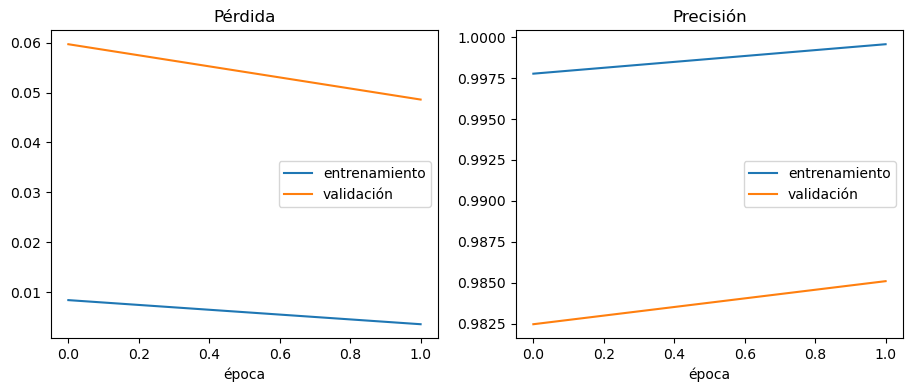

In [112]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(historial["perdida_ent"], label="entrenamiento")
ejes[0].plot(historial["perdida_val"], label="validación")
ejes[0].set_title("Pérdida"); ejes[0].set_xlabel("época"); ejes[0].legend()
ejes[1].plot(historial["acc_ent"], label="entrenamiento")
ejes[1].plot(historial["acc_val"], label="validación")
ejes[1].set_title("Precisión"); ejes[1].set_xlabel("época"); ejes[1].legend()
plt.show()

# Seccion 5: Evaluación

In [113]:
# Cargamos los mejores pesos guardados y ponemos la red en modo evaluación.
modelo.load_state_dict(torch.load("cnn_prohibicion.pt", map_location=device))
modelo.eval()

predicciones = []
probabilidades = []
etiquetas_reales = []

with torch.no_grad():
    for x, y in cargador_val:
        x = x.to(device)
        salida = modelo(x)
        prob = torch.softmax(salida, dim=1)
        predicciones.extend(salida.argmax(dim=1).cpu().numpy())
        probabilidades.extend(prob.cpu().numpy())
        etiquetas_reales.extend(y.numpy())

predicciones = np.asarray(predicciones)
probabilidades = np.asarray(probabilidades)
etiquetas_reales = np.asarray(etiquetas_reales)

precision_global = np.mean(predicciones == etiquetas_reales)
print(f"Precisión global en validación: {precision_global:.4f} ({precision_global * 100:.2f} %)")

PermissionError: [Errno 13] Permission denied: 'cnn_prohibicion.pt'

### Obtención de las predicciones

En esta evaluación se cargan los pesos guardados al finalizar el entrenamiento y se activa `modelo.eval()`. Esto es importante porque las capas de normalización por lotes (`BatchNorm2d`) deben utilizar las estadísticas acumuladas durante el entrenamiento y no recalcularlas con cada lote de validación.

`torch.no_grad()` desactiva el cálculo de gradientes. Durante la evaluación no se actualizan los pesos, por lo que esta opción reduce el consumo de memoria y acelera la inferencia. La red devuelve *logits*; aplicamos `softmax` únicamente para obtener probabilidades interpretables. La clase predicha es la que tiene el *logit* máximo.

La precisión global es la proporción de imágenes correctamente clasificadas. La validación se realiza sobre secuencias completas que no aparecen en entrenamiento, gracias al reparto realizado en la sección de datos. Por tanto, no se mezclan fotografías muy parecidas de una misma secuencia entre ambos conjuntos.

In [ ]:
# Matriz de confusión: fila = clase real, columna = clase predicha
n_clases = len(PROHIBICION)
matriz_confusion = np.zeros((n_clases, n_clases), dtype=int)
for real, predicha in zip(etiquetas_reales, predicciones):
    matriz_confusion[real, predicha] += 1

fig, ax = plt.subplots(figsize=(8, 7))
imagen = ax.imshow(matriz_confusion, cmap="Blues")
fig.colorbar(imagen, ax=ax, label="Número de imágenes")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión en validación")
ax.set_xticks(range(n_clases), PROHIBICION)
ax.set_yticks(range(n_clases), PROHIBICION)
for fila in range(n_clases):
    for columna in range(n_clases):
        ax.text(columna, fila, matriz_confusion[fila, columna],
                ha="center", va="center",
                color="white" if matriz_confusion[fila, columna] > matriz_confusion.max() / 2 else "black")
plt.tight_layout()
plt.show()

### Matriz de confusión

La matriz de confusión permite analizar los errores con más detalle que una única precisión global. Cada fila representa la clase real y cada columna la clase que ha predicho la red. Los valores de la diagonal son aciertos; los valores fuera de la diagonal indican confusiones entre dos tipos de señal.

Esta representación es especialmente útil en este problema porque algunas señales pueden tener una apariencia muy parecida. Si una clase presenta muchos valores fuera de la diagonal, conviene estudiar sus imágenes, su número de muestras y la posibilidad de ajustar el preprocesado o el entrenamiento.

In [ ]:
# Métricas por clase: precisión, recall y F1
filas_metricas = []
for indice, clase_original in enumerate(PROHIBICION):
    verdaderos_positivos = matriz_confusion[indice, indice]
    falsos_positivos = matriz_confusion[:, indice].sum() - verdaderos_positivos
    falsos_negativos = matriz_confusion[indice, :].sum() - verdaderos_positivos

    precision = verdaderos_positivos / (verdaderos_positivos + falsos_positivos) if verdaderos_positivos + falsos_positivos else 0.0
    recall = verdaderos_positivos / (verdaderos_positivos + falsos_negativos) if verdaderos_positivos + falsos_negativos else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    filas_metricas.append({
        "ClassId": clase_original,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Muestras": matriz_confusion[indice, :].sum(),
    })

metricas = pd.DataFrame(filas_metricas)
# Redondeamos los decimales sin usar metricas.style, que requiere jinja2.
display(metricas.round({"Precision": 3, "Recall": 3, "F1": 3}))

### Métricas por clase

La precisión indica qué proporción de las imágenes asignadas a una clase pertenece realmente a ella. El *recall* indica qué proporción de las imágenes reales de esa clase ha encontrado la red. La puntuación F1 combina ambas medidas mediante su media armónica.

Estas métricas se calculan a partir de la matriz de confusión. Se muestran junto al número de muestras porque una clase con pocos ejemplos puede tener una medida más variable. La comparación entre clases debe hacerse teniendo en cuenta ese desequilibrio.

In [ ]:
# Mostramos ejemplos de errores y de aciertos con la confianza de la red
indices_error = np.flatnonzero(predicciones != etiquetas_reales)
indices_acierto = np.flatnonzero(predicciones == etiquetas_reales)

def mostrar_ejemplos(indices, titulo, maximo=12):
    indices = indices[:maximo]
    if len(indices) == 0:
        print("No hay ejemplos para mostrar.")
        return
    columnas = 4
    filas = int(np.ceil(len(indices) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(12, 3 * filas))
    ejes = np.atleast_1d(ejes).ravel()
    for ax, indice in zip(ejes, indices):
        clase_real = PROHIBICION[etiquetas_reales[indice]]
        clase_predicha = PROHIBICION[predicciones[indice]]
        confianza = probabilidades[indice, predicciones[indice]]
        ax.imshow(X_val[indice], cmap="gray")
        ax.set_title(f"real: {clase_real} | pred: {clase_predicha}\nconf.: {confianza:.2f}")
        ax.axis("off")
    for ax in ejes[len(indices):]:
        ax.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

mostrar_ejemplos(indices_error, "Ejemplos de clasificación incorrecta")
mostrar_ejemplos(indices_acierto, "Ejemplos de clasificación correcta")

### Interpretación de ejemplos y conclusión de la evaluación

La última visualización permite comprobar si los errores tienen una causa comprensible, por ejemplo, baja iluminación, desenfoque, o una señal parcialmente oculta. La confianza mostrada es la probabilidad asociada a la clase predicha; una confianza alta en una predicción incorrecta señala un error especialmente relevante.

Los valores obtenidos en esta sección deben anotarse en la documentación final junto con el número de épocas, el reparto entrenamiento-validación, la arquitectura utilizada y los parámetros del optimizador. Como se evalúa el conjunto de validación, estos resultados sirven para comparar decisiones de diseño, pero no deben presentarse como una estimación completamente independiente del rendimiento final.

## Inferencia sobre detecciones de Alberto

Esta subsección conecta el detector de señales con la CNN. Cuando Alberto proporcione una imagen original y las cajas detectadas, solo hay que sustituir `RUTA_IMAGEN_DETECTADA` y `CAJAS_DETECTADAS` en la celda siguiente. El formato de cada caja debe ser `(x1, y1, x2, y2)`, donde `x` indica columnas y `y` indica filas.

El preprocesamiento debe coincidir con el utilizado durante el entrenamiento: recorte, escala de grises, redimensionado a 60 × 60 y conversión a tensor. Si Alberto entrega directamente los recortes, se puede utilizar la función `clasificar_recortes` sin necesidad de proporcionar las cajas.

La categoría `No conocida` no es una decimotercera neurona entrenada. Se obtiene mediante rechazo por confianza: si la probabilidad máxima de la CNN es menor que `UMBRAL_NO_CONOCIDA`, no se acepta ninguna de las 12 clases. El umbral es ajustable y debe comprobarse experimentalmente.

In [ ]:
def preparar_recorte_detectado(recorte, imagen_en_rgb=False):
    """Prepara un recorte BGR/RGB para que tenga el mismo formato que GTSRB."""
    assert recorte is not None and recorte.size > 0, "El recorte está vacío"
    if recorte.ndim == 3:
        codigo = cv.COLOR_RGB2GRAY if imagen_en_rgb else cv.COLOR_BGR2GRAY
        gris = cv.cvtColor(recorte, codigo)
    elif recorte.ndim == 2:
        gris = recorte
    else:
        raise ValueError("El recorte debe tener forma (alto, ancho) o (alto, ancho, 3)")
    return cv.resize(gris, (60, 60), interpolation=cv.INTER_LINEAR).astype(np.uint8)

UMBRAL_NO_CONOCIDA = 0.75

def clasificar_recortes(recortes, umbral=UMBRAL_NO_CONOCIDA):
    """Clasifica una lista de recortes y devuelve clase y confianza."""
    recortes_60 = np.stack([preparar_recorte_detectado(r) for r in recortes])
    entrada = a_tensor(recortes_60).to(device)
    modelo.eval()
    with torch.no_grad():
        logits = modelo(entrada)
        probabilidades = torch.softmax(logits, dim=1)
        indices = logits.argmax(dim=1).cpu().numpy()
        confianzas = probabilidades.max(dim=1).values.cpu().numpy()
    resultados = []
    for i, c in zip(indices, confianzas):
        c = float(c)
        if c < umbral:
            resultados.append({"Etiqueta": -1, "ClassId": None, "Clase": "No conocida", "Confianza": c})
        else:
            clase = PROHIBICION[int(i)]
            resultados.append({"Etiqueta": int(i), "ClassId": clase, "Clase": f"Clase {clase}", "Confianza": c})
    return resultados

def clasificar_detecciones(imagen_bgr, cajas):
    """Recorta las cajas de Alberto y clasifica cada detección."""
    alto, ancho = imagen_bgr.shape[:2]
    recortes, cajas_validas = [], []
    for caja in cajas:
        x1, y1, x2, y2 = [int(v) for v in caja]
        x1, x2 = max(0, x1), min(ancho, x2)
        y1, y2 = max(0, y1), min(alto, y2)
        if x2 <= x1 or y2 <= y1:
            print(f"Caja ignorada por ser inválida: {caja}")
            continue
        recortes.append(imagen_bgr[y1:y2, x1:x2])
        cajas_validas.append((x1, y1, x2, y2))
    resultados = clasificar_recortes(recortes) if recortes else []
    for resultado, caja in zip(resultados, cajas_validas):
        resultado["Caja"] = caja
    return resultados

In [ ]:
res = None
if detectadas:
    resultados_cnn = clasificar_recortes(detectadas)
    clases = list(map(lambda x:x["ClassId"],resultados_cnn))
    res = list(zip(detectadas,clases))
    '''for i in zip(detectadas, imagenes)
        cx, cy, radio = deteccion

        print(
            f"Centro: ({cx}, {cy}), radio: {radio} | "
            f"Resultado: {resultado['Clase']} | "
            f"ClassId: {resultado['ClassId']} | "
            f"Confianza: {resultado['Confianza']:.3f}"
        )'''
else:
    print("No se han detectado señales válidas.")
    

diccClases= {
    0:"Limite de velocidad 20",
    1:"Limite de velocidad 30",
    2:"Limite de velocidad 50",
    3:"Limite de velocidad de 60",
    4:"Limite de velocidad de 70",
    5:"Limite de velocidad de 80",
    7:"Limite de velocidad de 100",
    8:"Limite de velocidad de 120",
    9:"Prohibido adelantar",
    10:"Prohibido adelantar para camiones",
    15:"Circulacion Prohibida",
    16:"Prohibida la circulacion a camiones"
}

if res != None:
    plt.figure(figsize=(10, 7))
    for i in range(1,len(res)+1):
        plt.subplot(len(res), 1, i)
        plt.title(diccClases[res[i-1][1]]) 
        # Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
        plt.imshow(res[i-1][0],cmap="gray") 

# Experimentacion Global

In [ ]:
# Colocar ruta de la imagen a probar
ruta = "./imagenes/00010.ppm"

## Fase de Detección

In [ ]:
# Parametros de la funcion de binarización
vecindad_umbralizacion = 9
kernel_size_suavizado = 3
sigmax_suavizado = 2
limpiar_ruido = True

# Parametros de la funcion de detección de círculos
agrupacion = 1
distMin = 30 
sensibilidad = 50 
votosMin = 27 
radioMin = 7 
radioMax = 60

img,H,S,V = importar_imagen_y_HSV(ruta)
S_bin, S_bin_suavizado = binarizar_canal(S,H, vecindad_umbralizacion, kernel_size_suavizado, sigmax_suavizado, limpiar_ruido)
circulos,img_resultante = detectar_circulos(img, S_bin_suavizado, agrupacion, distMin, sensibilidad, votosMin, radioMin, radioMax)

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.title("1. Imagen Original")
# Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)) 

plt.subplot(2, 2, 3)
plt.title("2. Canal S (Umbralizado)")
plt.imshow(S_bin, cmap="gray")

plt.subplot(2, 2, 4)
plt.title("3. Canal S (Umbralizado + Suavizado)")
plt.imshow(S_bin_suavizado, cmap="gray")

plt.subplot(2, 2, 2)
plt.title("4. Imagen Original + Circulos")
# Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
plt.imshow(cv.cvtColor(img_resultante, cv.COLOR_BGR2RGB)) 
plt.tight_layout()
plt.show()

## Fase de Validación

In [ ]:
D_CAD = 30.0                  # escala acromática del índice CAD (rango válido 10-30; el artículo usa 19)
TAM_CNN = (60, 60)            # tamaño de entrada de la CNN
MARGEN_ROI = 0.10             # margen sobre el radio al recortar la señal
RADIO_MIN, RADIO_MAX = 8, 60  # radio exterior admitido para una señal (px)
ANILLO_PICO_MIN = 0.50        # fracción mínima de rojo en el pico del anillo
ANILLO_RATIO = (0.50, 0.95)   # rango de (radio interior / radio exterior) del anillo
FRAC_INTERIOR = 0.85          # el interior se mide dentro de 0.85 * radio interior
ACROMATICO_MIN = 0.30         # fracción mínima de píxeles acromáticos en el interior
ROJO_MAX = 0.35               # fracción máxima de píxeles rojos en el interior (el camión/coche rojo de las clases 9 y 10 ocupa hasta ~0.3)
COBERTURA_MIN = 0.75          # fracción mínima de la circunferencia del anillo que debe ser roja
BRILLO_MIN = 1.2              # el interior debe ser al menos 1.2 veces más brillante (gris) que el rojo del anillo

resultados = probar_validacion(ruta,circulos)  
detectadas = resultados["parches_cnn"]

## Fase de clasificación

In [ ]:
res = None
if detectadas:
    resultados_cnn = clasificar_recortes(detectadas)
    clases = list(map(lambda x:x["ClassId"],resultados_cnn))
    res = list(zip(detectadas,clases))
    '''for i in zip(detectadas, imagenes)
        cx, cy, radio = deteccion

        print(
            f"Centro: ({cx}, {cy}), radio: {radio} | "
            f"Resultado: {resultado['Clase']} | "
            f"ClassId: {resultado['ClassId']} | "
            f"Confianza: {resultado['Confianza']:.3f}"
        )'''
else:
    print("No se han detectado señales válidas.")
    

diccClases= {
    0:"Limite de velocidad 20",
    1:"Limite de velocidad 30",
    2:"Limite de velocidad 50",
    3:"Limite de velocidad de 60",
    4:"Limite de velocidad de 70",
    5:"Limite de velocidad de 80",
    7:"Limite de velocidad de 100",
    8:"Limite de velocidad de 120",
    9:"Prohibido adelantar",
    10:"Prohibido adelantar para camiones",
    15:"Circulacion Prohibida",
    16:"Prohibida la circulacion a camiones",
    None: "Sin Clasificación/No es una señal"
}

if res != None:
    plt.figure(figsize=(10, 7))
    for i in range(1,len(res)+1):
        plt.subplot(len(res), 1, i)
        plt.title(str(i) + ": " + diccClases[res[i-1][1]]) 
        # Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
        plt.imshow(res[i-1][0],cmap="gray") 

In [ ]:
# Colocar ruta de la imagen a probar
ruta = "./imagenes/00002.ppm"
# Parametros de la funcion de binarización
vecindad_umbralizacion = 9
kernel_size_suavizado = 3
sigmax_suavizado = 2
limpiar_ruido = True

# Parametros de la funcion de detección de círculos
agrupacion = 1
distMin = 30 
sensibilidad = 50 
votosMin = 27 
radioMin = 7 
radioMax = 60

img,H,S,V = importar_imagen_y_HSV(ruta)
S_bin, S_bin_suavizado = binarizar_canal(S,H, vecindad_umbralizacion, kernel_size_suavizado, sigmax_suavizado, limpiar_ruido)
circulos,img_resultante = detectar_circulos(img, S_bin_suavizado, agrupacion, distMin, sensibilidad, votosMin, radioMin, radioMax)

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.title("1. Imagen Original")
# Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)) 

plt.subplot(2, 2, 3)
plt.title("2. Canal S (Umbralizado)")
plt.imshow(S_bin, cmap="gray")

plt.subplot(2, 2, 4)
plt.title("3. Canal S (Umbralizado + Suavizado)")
plt.imshow(S_bin_suavizado, cmap="gray")

plt.subplot(2, 2, 2)
plt.title("4. Imagen Original + Circulos")
# Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
plt.imshow(cv.cvtColor(img_resultante, cv.COLOR_BGR2RGB)) 
plt.tight_layout()
plt.show()

D_CAD = 30.0                  # escala acromática del índice CAD (rango válido 10-30; el artículo usa 19)
TAM_CNN = (60, 60)            # tamaño de entrada de la CNN
MARGEN_ROI = 0.10             # margen sobre el radio al recortar la señal
RADIO_MIN, RADIO_MAX = 8, 60  # radio exterior admitido para una señal (px)
ANILLO_PICO_MIN = 0.50        # fracción mínima de rojo en el pico del anillo
ANILLO_RATIO = (0.50, 0.95)   # rango de (radio interior / radio exterior) del anillo
FRAC_INTERIOR = 0.85          # el interior se mide dentro de 0.85 * radio interior
ACROMATICO_MIN = 0.30         # fracción mínima de píxeles acromáticos en el interior
ROJO_MAX = 0.35               # fracción máxima de píxeles rojos en el interior (el camión/coche rojo de las clases 9 y 10 ocupa hasta ~0.3)
COBERTURA_MIN = 0.75          # fracción mínima de la circunferencia del anillo que debe ser roja
BRILLO_MIN = 1.2              # el interior debe ser al menos 1.2 veces más brillante (gris) que el rojo del anillo

resultados = probar_validacion(ruta,circulos)  
detectadas = resultados["parches_cnn"]
res = None
if detectadas:
    resultados_cnn = clasificar_recortes(detectadas)
    clases = list(map(lambda x:x["ClassId"],resultados_cnn))
    res = list(zip(detectadas,clases))
    '''for i in zip(detectadas, imagenes)
        cx, cy, radio = deteccion

        print(
            f"Centro: ({cx}, {cy}), radio: {radio} | "
            f"Resultado: {resultado['Clase']} | "
            f"ClassId: {resultado['ClassId']} | "
            f"Confianza: {resultado['Confianza']:.3f}"
        )'''
else:
    print("No se han detectado señales válidas.")
    

diccClases= {
    0:"Limite de velocidad 20",
    1:"Limite de velocidad 30",
    2:"Limite de velocidad 50",
    3:"Limite de velocidad de 60",
    4:"Limite de velocidad de 70",
    5:"Limite de velocidad de 80",
    7:"Limite de velocidad de 100",
    8:"Limite de velocidad de 120",
    9:"Prohibido adelantar",
    10:"Prohibido adelantar para camiones",
    15:"Circulacion Prohibida",
    16:"Prohibida la circulacion a camiones",
    None: "Sin Clasificación/No es una señal"
}

if res != None:
    plt.figure(figsize=(10, 7))
    for i in range(1,len(res)+1):
        plt.subplot(len(res), 1, i)
        plt.title(str(i) + ": " + diccClases[res[i-1][1]]) 
        # Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
        plt.imshow(res[i-1][0],cmap="gray") 